[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Nicolenki7/ETFbook-data-analytics-case-study/blob/main/notebooks/etfbook_flows_colab.ipynb)

> **En 30 segundos:** 4 ETFs y 3 meses: SPY se lleva el 40 % del flujo neto y 3 de 12 combinaciones ETF-mes cierran con salidas.
>
> - SPY: 16.100 millones de USD (39,9 % del flujo del trimestre)
> - 3 de 12 combinaciones ETF-mes en negativo
> - Extracto trimestral: describe el periodo, no es tendencia
>
> Los resultados ya están ejecutados: no hace falta correr nada para leerlos.

# ETFbook · flujos netos de ETFs

**Que responde este cuaderno**

1. Cuanto flujo neto entra o sale en el trimestre.
2. Que ETF se lleva ese flujo.
3. Si el dinero entra de forma sostenida o en un solo mes.
4. Que region domina.

**Datos**: `etf_flows_trend_analysis_2025.csv` (12 filas: 4 ETFs por 3 meses). Se descarga por URL al ejecutar.

**Como correrlo**: Runtime > Run all. Solo pandas y matplotlib.

**Escala**: es un extracto trimestral de 4 ETFs, no una serie historica completa.

In [1]:
import io, pathlib, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

URL = ('https://raw.githubusercontent.com/Nicolenki7/ETFbook-data-analytics-case-study/'
       'main/etf_flows_analysis/data/etf_flows_trend_analysis_2025.csv')
pathlib.Path('outputs').mkdir(exist_ok=True)

with urllib.request.urlopen(URL) as r:
    df = pd.read_csv(io.BytesIO(r.read()))

df['date'] = pd.to_datetime(df['date'])
df['mes'] = df['date'].dt.strftime('%Y-%m')

print('filas:', len(df), '| columnas:', list(df.columns))
print('ETFs:', sorted(df['etf_ticker'].unique()), '| meses:', sorted(df['mes'].unique()))
print('unidad: millones de USD')
df.head()

filas: 12 | columnas: ['date', 'etf_ticker', 'net_flows_usd_m', 'region', 'mes']
ETFs: ['IEMG', 'IVV', 'QQQ', 'SPY'] | meses: ['2025-01', '2025-02', '2025-03']
unidad: millones de USD


,date,etf_ticker,net_flows_usd_m,region,mes
0,2025-01-31,SPY,5200,US,2025-01
1,2025-02-28,SPY,6100,US,2025-02
2,2025-03-31,SPY,4800,US,2025-03
3,2025-01-31,QQQ,4300,US,2025-01
4,2025-02-28,QQQ,5100,US,2025-02


## 1. Cuanto dinero se movio

Signo incluido: un flujo neto negativo es salida de capital, no venta baja.

RESPUESTA: 4 ETFs acumulan 40,400 millones de USD en 3 meses.

mes
2025-01    12600
2025-02    14800
2025-03    13000

RESPUESTA: el mejor mes es 2025-02 con 14,800 millones y el peor 2025-01 con 12,600.


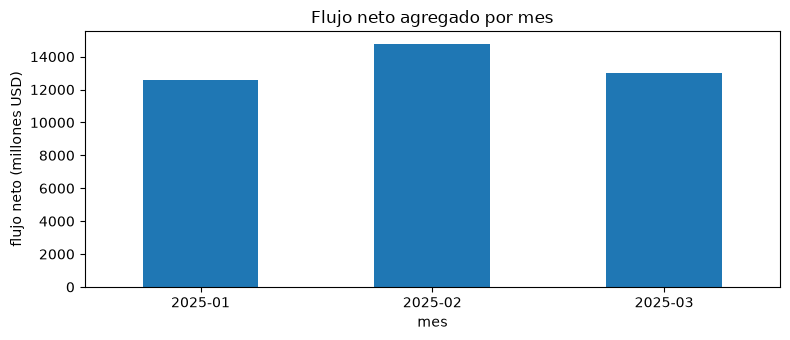

In [2]:
total = df['net_flows_usd_m'].sum()
n_meses = df['mes'].nunique()
n_etfs = df['etf_ticker'].nunique()

print(f'RESPUESTA: {n_etfs} ETFs acumulan {total:,.0f} millones de USD en {n_meses} meses.')

mes = df.groupby('mes')['net_flows_usd_m'].sum()
print()
print(mes.to_string())

print()
print(f'RESPUESTA: el mejor mes es {mes.idxmax()} con {mes.max():,.0f} millones y el peor {mes.idxmin()} con {mes.min():,.0f}.')

ax = mes.plot(kind='bar', figsize=(8, 3.5), rot=0)
ax.set_ylabel('flujo neto (millones USD)')
ax.set_title('Flujo neto agregado por mes')
plt.tight_layout()
plt.savefig('outputs/flujo_mensual.png', dpi=150)
plt.show()

## 2. Quien se lleva el flujo

Cuota por ETF: con 4 fondos, la concentracion es la pregunta clave.

            flujo_total  meses   media  cuota_pct
etf_ticker                                       
SPY               16100      3  5366.7       39.9
QQQ               14100      3  4700.0       34.9
IVV               12100      3  4033.3       30.0
IEMG              -1900      3  -633.3       -4.7

RESPUESTA: SPY se lleva el 39.9 % del flujo neto del periodo (16,100 millones).


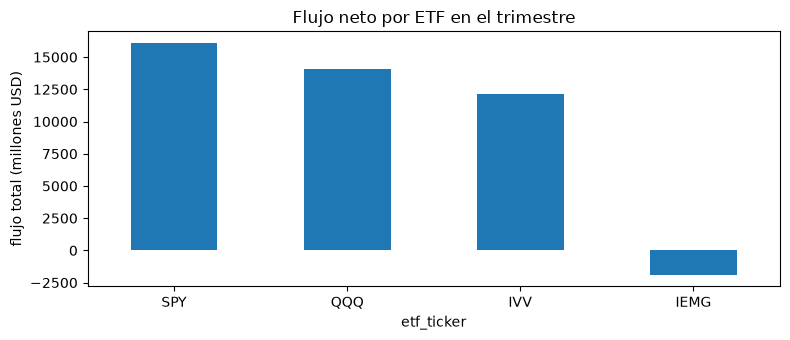

In [3]:
resumen = (df.groupby('etf_ticker')['net_flows_usd_m']
             .agg(flujo_total='sum', meses='count', media='mean')
             .sort_values('flujo_total', ascending=False)
             .round(1))
resumen['cuota_pct'] = (resumen['flujo_total'] / resumen['flujo_total'].sum() * 100).round(1)
print(resumen.to_string())

primero = resumen.index[0]
print()
print(f'RESPUESTA: {primero} se lleva el {resumen["cuota_pct"].iloc[0]} % del flujo neto del periodo ({resumen["flujo_total"].iloc[0]:,.0f} millones).')

ax = resumen['flujo_total'].plot(kind='bar', figsize=(8, 3.5), rot=0)
ax.set_ylabel('flujo total (millones USD)')
ax.set_title('Flujo neto por ETF en el trimestre')
plt.tight_layout()
plt.savefig('outputs/flujo_etf.png', dpi=150)
plt.show()

## 3. Entrada sostenida o un solo mes

Un total positivo puede esconder meses en rojo. Miramos el signo mes a mes por ETF.

etf_ticker  IEMG   IVV   QQQ   SPY
mes                               
2025-01     -800  3900  4300  5200
2025-02     -600  4200  5100  6100
2025-03     -500  4000  4700  4800

RESPUESTA: de 12 combinaciones ETF-mes, 3 son de salida de capital.


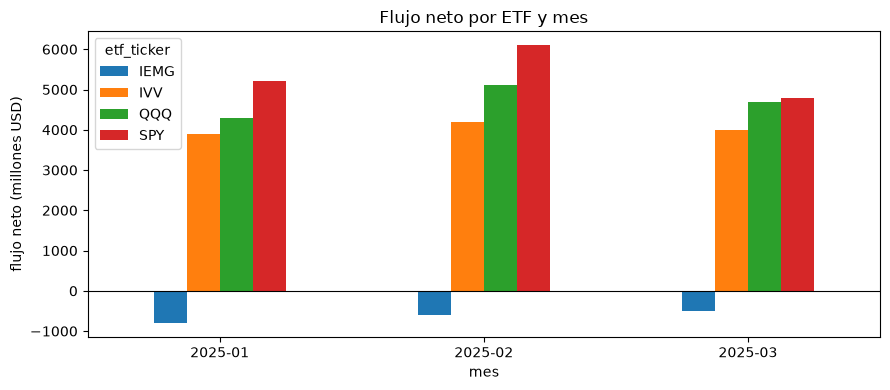

In [4]:
pivote = df.pivot_table(index='mes', columns='etf_ticker', values='net_flows_usd_m', aggfunc='sum')
print(pivote.to_string())

meses_negativos = int((pivote < 0).sum().sum())
total_celdas = pivote.size
print()
print(f'RESPUESTA: de {total_celdas} combinaciones ETF-mes, {meses_negativos} son de salida de capital.')

ax = pivote.plot(kind='bar', figsize=(9, 4), rot=0)
ax.set_ylabel('flujo neto (millones USD)')
ax.set_title('Flujo neto por ETF y mes')
ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('outputs/flujo_etf_mes.png', dpi=150)
plt.show()

## 4. Que region domina

La columna `region` agrupa los ETFs por mercado de origen. Ojo: si una region tiene flujo negativo, su cuota sobre el total no es un porcentaje directo y este cuaderno lo dice en lugar de forzarlo.

region
US    42300
EM    -1900

RESPUESTA: US concentra 42,300 millones, el 100.0 % de las entradas brutas (42,300 millones).
La region EM cierra en negativo con -1,900 millones, asi que su cuota no se puede leer como porcentaje del total: por eso no se calcula 100 minus lo anterior.


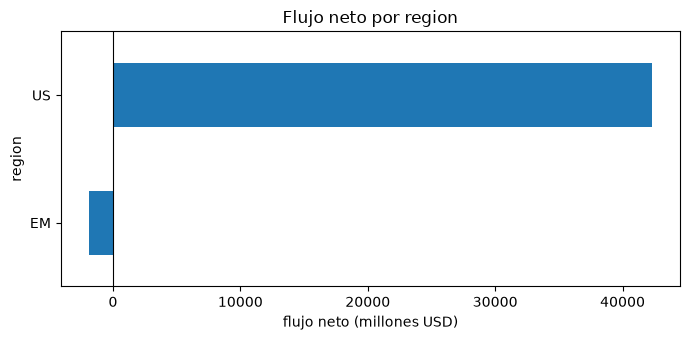

In [5]:
reg = df.groupby('region')['net_flows_usd_m'].sum().sort_values(ascending=False)
print(reg.to_string())

entradas = reg[reg > 0].sum()
salidas = reg[reg < 0].sum()
lider = reg.index[0]
cuota_lider = reg.iloc[0] / entradas * 100

print()
print(f'RESPUESTA: {lider} concentra {reg.iloc[0]:,.0f} millones, el {cuota_lider:.1f} % de las entradas brutas ({entradas:,.0f} millones).')
if salidas < 0:
    print(f'La region {reg.index[-1]} cierra en negativo con {salidas:,.0f} millones, asi que su cuota no se puede leer como porcentaje del total: por eso no se calcula 100 minus lo anterior.')
else:
    print('Todas las regiones cierran en positivo, asi que las cuotas suman 100 %.')

ax = reg.sort_values().plot(kind='barh', figsize=(7, 3.5))
ax.set_xlabel('flujo neto (millones USD)')
ax.set_title('Flujo neto por region')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('outputs/flujo_region.png', dpi=150)
plt.show()

## Limites

- 12 observaciones y 3 meses: describe el trimestre, no una tendencia.
- El flujo neto no es rentabilidad: mide entradas y salidas de dinero, no desempeno del fondo.
- La region viene dada por el dataset; no se deduce del ticker.
- Sin datos de patrimonio (AUM) no se puede relativizar el flujo sobre el tamano del fondo.
- Con una region en negativo, las cuotas porcentuales se calculan sobre entradas brutas y se explicita la base.